# Part 1. Data Cleaning

### Load Austin 311 Data and Analyse it

austin_311.csv data source: https://data.austintexas.gov/Utilities-and-City-Services/Austin-311-Public-Data/xwdj-i9he/about_data

In [2]:
import pandas as pd
import numpy as np

In [53]:
df_311=pd.read_csv("data/austin_311.csv")
df_311.head()

C:\Users\stanv\anaconda3\lib\site-packages\IPython\core\interactiveshell.py:3444: DtypeWarning: Columns (10) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,Service Request (SR) Number,SR Description,Owning Department,Method Received,SR Status,Status Change Date,Created Date,Last Update Date,Close Date,SR Location,...,Zip Code,County,State Plane X Coordinate,State Plane Y Coordinate,Latitude Coordinate,Longitude Coordinate,(Latitude.Longitude),Council District,Map Page,Map Tile
0,18-00000002,Traffic Signal - Maintenance,Transportation,Phone,Closed,2018 Feb 01 08:49:37 AM,2018 Jan 01 12:01:16 AM,2018 Feb 01 08:49:37 AM,2018 Feb 01 08:49:37 AM,"BURNET RD & RESEARCH BLVD SVRD NB, AUSTIN, TX ...",...,78758.0,TRAVIS,3.118626e+06,1.010921e+07,30.373506,-97.726294,POINT (-97.72629374 30.37350576),7.0,495U,MK31
1,18-00000067,Injured / Sick Animal,Animal Services Office,Phone,Closed,2018 Oct 21 06:44:48 PM,2018 Jan 01 12:13:22 AM,2018 Oct 21 06:44:48 PM,2018 Oct 21 06:44:48 PM,"7000 KILDARE CV, AUSTIN, TX 78724",...,78724.0,TRAVIS,3.145601e+06,1.008266e+07,30.298745,-97.642812,POINT (-97.64281229 30.29874468),1.0,557Y,MP25
2,18-00000113,Traffic Signal - Maintenance,Transportation,Phone,Closed,2018 Feb 13 12:36:00 PM,2018 Jan 01 12:23:38 AM,2018 Feb 13 11:44:29 AM,2018 Feb 13 12:36:00 PM,"8900 BURNET RD, AUSTIN, TX 78757",...,78757.0,TRAVIS,3.118479e+06,1.010886e+07,30.372537,-97.726785,POINT (-97.72678543 30.37253654),7.0,495Y,MK31
3,18-00000121,Sign - Traffic Sign Maintenance,Transportation,Phone,Closed,2018 Jan 02 11:33:12 AM,2018 Jan 01 12:27:28 AM,2018 Feb 01 04:41:10 PM,2018 Jan 02 11:33:12 AM,"ESCARPMENT BLVD & CONVICT HILL RD, AUSTIN, TX ...",...,78749.0,NaN,3.074931e+06,1.005448e+07,30.225795,-97.868666,POINT (-97.86866614 30.22579524),NaN,642A,MC18
4,18-00000126,Sign - Traffic Sign Maintenance,Transportation,Phone,Closed,2018 Feb 02 01:02:15 AM,2018 Jan 01 12:29:42 AM,2018 Feb 02 01:02:15 AM,2018 Feb 02 01:02:15 AM,"8500 N FM 620 RD, AUSTIN, TX 78726",...,78726.0,NaN,3.080953e+06,1.012659e+07,30.423646,-97.844495,POINT (-97.8444953 30.42364647),NaN,462L,MD35


In [54]:
df_311.shape

(2020304, 23)

In [5]:
df_311.columns.tolist()

['Service Request (SR) Number',
 'SR Description',
 'Owning Department',
 'Method Received',
 'SR Status',
 'Status Change Date',
 'Created Date',
 'Last Update Date',
 'Close Date',
 'SR Location',
 'Street Number',
 'Street Name',
 'City',
 'Zip Code',
 'County',
 'State Plane X Coordinate',
 'State Plane Y Coordinate',
 'Latitude Coordinate',
 'Longitude Coordinate',
 '(Latitude.Longitude)',
 'Council District',
 'Map Page',
 'Map Tile']

### Understand the 'Created Date' column

In [55]:
df_311['Created Date'].head()

0    2018 Jan 01 12:01:16 AM
1    2018 Jan 01 12:13:22 AM
2    2018 Jan 01 12:23:38 AM
3    2018 Jan 01 12:27:28 AM
4    2018 Jan 01 12:29:42 AM
Name: Created Date, dtype: object

In [56]:
df_311['Created Date'].dtype

## dtype(0) means pandas sees this as TEXT. We need to fix it. 

dtype('O')

In [57]:
df_311['Created Date'].min(), df_311['Created Date'].max()

('2018 Apr 01 01:02:42 PM', '2026 Sep 19 12:59:12 PM')

In [58]:
## Convert Created Date to a real date

df_311["Created Date"]=pd.to_datetime(df_311["Created Date"], format = "%Y %b %d %I:%M:%S %p")

In [59]:
df_311['Created Date'].dtype

dtype('<M8[ns]')

In [60]:
df_311['Created Date'].head()

0   2018-01-01 00:01:16
1   2018-01-01 00:13:22
2   2018-01-01 00:23:38
3   2018-01-01 00:27:28
4   2018-01-01 00:29:42
Name: Created Date, dtype: datetime64[ns]

In [61]:
df_311['Created Date'].isnull().sum()

0

### Create our daily 311 dataset

Right now, we have ~2 million individual service requests.

But our research question is:
How many 311 requests does Austin receive each day?

So we're going to transform:
2,020,304 individual rows → ~2,900 daily rows

This daily aggregation is the core transformation of our project.

In [18]:
#daily_311= df_311.copy()

In [62]:
# Remove time portion
df_311['date']= df_311['Created Date'].dt.normalize()

daily_311 = ( 
    df_311[
        df_311['date']>="2018-01-01" # keeping data 2018 - September 2026
        #(df_311['date']>="2018-01-01") & (df_311['date']<"2026-01-01") # keeping data 2018 - 2025
    ]
    .groupby("date")
    .size()
    .reset_index(name='311_requests')
)

daily_311.head()

,date,311_requests
0,2018-01-01,162
1,2018-01-02,290
2,2018-01-03,355
3,2018-01-04,320
4,2018-01-05,274


In [63]:
daily_311.shape #successfully transformed ~2 million individual 311 records into 2,921 daily observations.

(3183, 2)

In [64]:
daily_311.tail()

,date,311_requests
3178,2026-09-15,798
3179,2026-09-16,814
3180,2026-09-17,863
3181,2026-09-18,791
3182,2026-09-19,497


In [65]:
daily_311['date'].min(), daily_311['date'].max()

(Timestamp('2018-01-01 00:00:00'), Timestamp('2026-09-19 00:00:00'))

#### Sanity check on daily_311

In [66]:
daily_311.head(10)

,date,311_requests
0,2018-01-01,162
1,2018-01-02,290
2,2018-01-03,355
3,2018-01-04,320
4,2018-01-05,274
5,2018-01-06,220
6,2018-01-07,204
7,2018-01-08,366
8,2018-01-09,362
9,2018-01-10,309


In [67]:
daily_311.describe()

,311_requests
count,3183.000000
mean,634.716934
std,317.964883
min,68.000000
25%,431.000000
50%,582.000000
75%,840.000000
max,5909.000000


3,183 daily observations — exactly matching Jan 1, 2018 through Sep 19, 2026.

Average: 635 requests/day

Median: 582/day

Standard deviation: 318/day

Minimum: 68/day

Maximum: 5,909/day

The mean being higher than the median suggests some high-demand days are pulling the average upward. That's something we'll investigate later rather than assuming why.

In [68]:
# Save daily_311 into a CSV file
daily_311.to_csv("data/austin_311_daily.csv",index=False)

In [69]:
# Verify file was created
import os
os.path.exists("data/austin_311_daily.csv")

True

### Analysing Weather Data 

data source: https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND%3AUSW00013958/detail?utm_source=chatgpt.com
USW00013958
AUSTIN CAMP MABRY, TX US

In [29]:
os.listdir('data')

['4396445.csv', 'austin_311.csv', 'austin_311_daily.csv']

In [30]:
weather = pd.read_csv("data/4396445.csv")
weather.shape

(3182, 46)

In [31]:
weather.columns.tolist()

['STATION',
 'NAME',
 'LATITUDE',
 'LONGITUDE',
 'ELEVATION',
 'DATE',
 'AWND',
 'AWND_ATTRIBUTES',
 'PGTM',
 'PGTM_ATTRIBUTES',
 'PRCP',
 'PRCP_ATTRIBUTES',
 'SNOW',
 'SNOW_ATTRIBUTES',
 'SNWD',
 'SNWD_ATTRIBUTES',
 'TAVG',
 'TAVG_ATTRIBUTES',
 'TMAX',
 'TMAX_ATTRIBUTES',
 'TMIN',
 'TMIN_ATTRIBUTES',
 'WDF2',
 'WDF2_ATTRIBUTES',
 'WDF5',
 'WDF5_ATTRIBUTES',
 'WSF2',
 'WSF2_ATTRIBUTES',
 'WSF5',
 'WSF5_ATTRIBUTES',
 'WT01',
 'WT01_ATTRIBUTES',
 'WT02',
 'WT02_ATTRIBUTES',
 'WT03',
 'WT03_ATTRIBUTES',
 'WT04',
 'WT04_ATTRIBUTES',
 'WT05',
 'WT05_ATTRIBUTES',
 'WT06',
 'WT06_ATTRIBUTES',
 'WT07',
 'WT07_ATTRIBUTES',
 'WT08',
 'WT08_ATTRIBUTES']

In [32]:
weather.head()

,STATION,NAME,LATITUDE,LONGITUDE,ELEVATION,DATE,AWND,AWND_ATTRIBUTES,PGTM,PGTM_ATTRIBUTES,...,WT04,WT04_ATTRIBUTES,WT05,WT05_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT07,WT07_ATTRIBUTES,WT08,WT08_ATTRIBUTES
0,USW00013958,"AUSTIN CAMP MABRY, TX US",30.3208,-97.7604,204.2,2018-01-01,7.61,",,W",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USW00013958,"AUSTIN CAMP MABRY, TX US",30.3208,-97.7604,204.2,2018-01-02,4.92,",,W",NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,",,W",NaN,NaN,1.0,",,W"
2,USW00013958,"AUSTIN CAMP MABRY, TX US",30.3208,-97.7604,204.2,2018-01-03,2.24,",,W",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USW00013958,"AUSTIN CAMP MABRY, TX US",30.3208,-97.7604,204.2,2018-01-04,2.01,",,W",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USW00013958,"AUSTIN CAMP MABRY, TX US",30.3208,-97.7604,204.2,2018-01-05,2.46,",,W",NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Create our clean weather dataset

We'll keep:

DATE → date for joining

TAVG → average temperature

TMAX → maximum temperature

TMIN → minimum temperature

PRCP → precipitation

AWND → average wind speed


In [34]:
weather_clean= weather[['DATE','TAVG','TMAX','TMIN','PRCP','AWND']].copy()

In [35]:
weather_clean['DATE']=pd.to_datetime(weather_clean['DATE'])
weather_clean.head(3)

,DATE,TAVG,TMAX,TMIN,PRCP,AWND
0,2018-01-01,NaN,32,25,0.0,7.61
1,2018-01-02,NaN,32,26,0.0,4.92
2,2018-01-03,NaN,56,22,0.0,2.24


In [36]:
weather_clean.isnull().sum()

DATE       0
TAVG    3182
TMAX       0
TMIN       0
PRCP       0
AWND       2
dtype: int64

### Feature Engineering

We don't have values for TAVG so we use this formula:

TAVG=(TMAX+TMIN​)/2

In [38]:
weather_clean["TAVG"]=(weather_clean['TMAX']+weather_clean['TMIN'])/2

weather_clean.head(3)

,DATE,TAVG,TMAX,TMIN,PRCP,AWND
0,2018-01-01,28.5,32,25,0.0,7.61
1,2018-01-02,29.0,32,26,0.0,4.92
2,2018-01-03,39.0,56,22,0.0,2.24


In [39]:
weather_clean[weather_clean['AWND'].isnull()]

,DATE,TAVG,TMAX,TMIN,PRCP,AWND
1415,2021-11-16,73.5,82,65,0.0,NaN
1777,2022-11-13,47.0,59,35,0.0,NaN


Since we're building a daily predictive dataset, I don't want to drop these two dates. We need those dates available when we eventually merge weather with the 311 data.

For only 2 missing observations, we'll use linear interpolation based on the surrounding days. This is preferable to filling them with the overall average because wind speed can vary seasonally.

In [40]:
weather_clean['AWND']=weather_clean['AWND'].interpolate()

In [41]:
weather_clean.isnull().sum()

DATE    0
TAVG    0
TMAX    0
TMIN    0
PRCP    0
AWND    0
dtype: int64

In [43]:
weather_clean.describe()

,TAVG,TMAX,TMIN,PRCP,AWND
count,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000
mean,71.827310,82.769013,60.885607,0.087011,4.735129
std,14.696916,15.483441,14.752686,0.320798,2.071653
min,16.500000,24.000000,7.000000,0.000000,0.220000
25%,60.625000,73.000000,49.000000,0.000000,3.130000
50%,74.500000,85.000000,64.000000,0.000000,4.700000
75%,84.500000,95.000000,74.000000,0.000000,6.040000
max,94.500000,110.000000,84.000000,3.730000,12.530000


In [44]:
weather_clean = weather_clean.rename(columns = {
    "DATE":"date",
    "TAVG":"avg_temp_f",
    "TMAX":"max_temp_f",
    "TMIN":"min_temp_f",
    "PRCP":"precipitation_in",
    "AWND":"avg_wind_mph"
})

weather_clean.head(3)

,date,avg_temp_f,max_temp_f,min_temp_f,precipitation_in,avg_wind_mph
0,2018-01-01,28.5,32,25,0.0,7.61
1,2018-01-02,29.0,32,26,0.0,4.92
2,2018-01-03,39.0,56,22,0.0,2.24


In [47]:
weather_clean.to_csv("data/austin_weather.csv",index=False)

os.path.exists("data/austin_weather.csv")

True

# Part 2: Feature Engineering

### Merge both datasets into one

311 + weather

In [70]:
import pandas as pd

daily_311=pd.read_csv('data/austin_311_daily.csv')
weather_clean=pd.read_csv('data/austin_weather.csv')

daily_311['date']= pd.to_datetime(daily_311['date'])
weather_clean['date']=pd.to_datetime(weather_clean['date'])

In [71]:
daily_311.shape, weather_clean.shape

((3183, 2), (3182, 6))

Why are the row counts different? This is intentional.

Our 311 dataset currently ends at December 31, 2025, because we created it with: df_311["date"] < "2026-01-01"

Remember our modeling plan:

2018–2024 → TRAIN

2025 → TEST

Jan–Sep 2026 → FINAL HOLDOUT

So eventually we do need to bring the 2026 311 data back in. We deliberately didn't include it in daily_311 earlier.

2018 ─────────────────────────────── 2024 | 2025 | Jan–Sep 2026
         
         TRAIN                                   TEST   FINAL HOLDOUT



In [74]:
daily_311['date'].min(), daily_311['date'].max()

(Timestamp('2018-01-01 00:00:00'), Timestamp('2026-09-19 00:00:00'))

In [75]:
weather_clean['date'].min(), weather_clean['date'].max()

(Timestamp('2018-01-01 00:00:00'), Timestamp('2026-09-17 00:00:00'))

daily_311 has 3,183 rows, but the date range from Jan 1, 2018 through Sep 19, 2026 contains 3,184 calendar days.

That means one calendar date may be absent from daily_311.

Check for missing 311 dates:

In [76]:
#Check for missing 311 dates
full_dates = pd.date_range(
    daily_311["date"].min(),
    daily_311["date"].max(),
    freq="D"
)

missing_311_dates = full_dates.difference(daily_311["date"])

missing_311_dates

DatetimeIndex(['2018-09-15'], dtype='datetime64[ns]', freq=None)

In [77]:
#Check the raw 311 data for September 15, 2018
df_311[
    df_311["date"] == "2018-09-15"
].shape

(0, 24)

The raw dataset seems to have a collection/reporting gap that day.

So let's investigate what day September 15, 2018 was and look at the neighboring request counts.

In [78]:
daily_311[
    (daily_311["date"] >= "2018-09-12") &
    (daily_311["date"] <= "2018-09-18")
]

,date,311_requests
254,2018-09-12,526
255,2018-09-13,472
256,2018-09-14,425
257,2018-09-16,389
258,2018-09-17,775
259,2018-09-18,625


In [79]:
daily_311[
    daily_311["311_requests"] == 0
]

,date,311_requests


There are no other zero-request days in the entire dataset.

That makes 2018-09-15 much more suspicious. We have:

3,183 observed dates

Only one missing calendar date

That date has 0 raw records

Every other day has at least some requests

The surrounding days have hundreds of requests

So, we shouldn't simply insert 0 and call it a real observation.

Also, we don't want to use a random average such as 635, because that's an invented target too.

Instead,

Let's treat Sep 15 as a missing observation, then impute it using the surrounding time-series information.

Sep 15 was a Saturday, so weekday/weekend patterns matter. We should ideally use other Saturdays around that period to calculate the average

In [80]:
daily_311[
    (daily_311["date"] >= "2018-08-01") &
    (daily_311["date"] <= "2018-10-15")
].assign(
    day_of_week=lambda x: x["date"].dt.day_name()
).query(
    "day_of_week == 'Saturday'"
)

,date,311_requests,day_of_week
215,2018-08-04,301,Saturday
222,2018-08-11,330,Saturday
229,2018-08-18,289,Saturday
236,2018-08-25,270,Saturday
243,2018-09-01,341,Saturday
250,2018-09-08,271,Saturday
263,2018-09-22,423,Saturday
270,2018-09-29,336,Saturday
277,2018-10-06,267,Saturday
284,2018-10-13,283,Saturday


Let's use local Saturday imputation.

The cleanest approach for this project is to take the average of the surrounding comparable Saturdays:

Sep 8 = 271
Sep 22 = 423
$$ \frac{271 + 423}{2} = 347 $$

So we can reasonably impute:

Sep 15, 2018 → 347 requests

In [81]:
daily_311 = pd.concat([
    daily_311,
    pd.DataFrame({
        "date": [pd.Timestamp("2018-09-15")],
        "311_requests": [347]
    })
], ignore_index=True).sort_values("date").reset_index(drop=True)


#verify
daily_311[
    (daily_311["date"] >= "2018-09-12") &
    (daily_311["date"] <= "2018-09-18")
]

,date,311_requests
254,2018-09-12,526
255,2018-09-13,472
256,2018-09-14,425
257,2018-09-15,347
258,2018-09-16,389
259,2018-09-17,775
260,2018-09-18,625


In [82]:
daily_311.to_csv('data/austin_311_daily.csv', index=False)

### Create master modeling dataset

One row = one calendar day, with 311 demand + weather for that same day.

We'll use an inner merge because:

311 data → through Sep 19, 2026

Weather → through Sep 17, 2026

An inner merge automatically keeps only dates available in both datasets.

So Sep 18 and Sep 19 disappear from the modeling dataset rather than us making up weather data.

In [83]:
model_df = pd.merge(daily_311,weather_clean, on='date', how='inner')

model_df.shape

(3182, 7)

In [84]:
model_df.head()

,date,311_requests,avg_temp_f,max_temp_f,min_temp_f,precipitation_in,avg_wind_mph
0,2018-01-01,162,28.5,32,25,0.0,7.61
1,2018-01-02,290,29.0,32,26,0.0,4.92
2,2018-01-03,355,39.0,56,22,0.0,2.24
3,2018-01-04,320,42.5,55,30,0.0,2.01
4,2018-01-05,274,53.0,62,44,0.0,2.46


In [85]:
model_df.tail()

,date,311_requests,avg_temp_f,max_temp_f,min_temp_f,precipitation_in,avg_wind_mph
3177,2026-09-13,414,90.5,102,79,0.0,7.61
3178,2026-09-14,880,90.0,101,79,0.0,6.71
3179,2026-09-15,798,91.0,103,79,0.0,6.71
3180,2026-09-16,814,90.0,101,79,0.0,5.14
3181,2026-09-17,863,87.5,98,77,0.0,4.25


In [87]:
model_df.isnull().sum()

date                0
311_requests        0
avg_temp_f          0
max_temp_f          0
min_temp_f          0
precipitation_in    0
avg_wind_mph        0
dtype: int64

In [88]:
model_df.dtypes

date                datetime64[ns]
311_requests                 int64
avg_temp_f                 float64
max_temp_f                   int64
min_temp_f                   int64
precipitation_in           float64
avg_wind_mph               float64
dtype: object

### Create the calendar features

day of week → Monday vs Saturday, etc.

weekend → weekends may have different request volumes

month → seasonal patterns

year → long-term changes in Austin's 311 volume

** day_of_week: Mon - 0, Tue - 1, .. Sat - 5, Sun - 6

** is_weekend: Weekday  → 0, Weekend  → 1

In [90]:
model_df['day_of_week']= model_df['date'].dt.dayofweek

model_df['is_weekend'] = (model_df['day_of_week']>=5).astype(int)

model_df['month']=model_df['date'].dt.month

model_df['year']=model_df['date'].dt.year

model_df.head()

,date,311_requests,avg_temp_f,max_temp_f,min_temp_f,precipitation_in,avg_wind_mph,day_of_week,is_weekend,month,year
0,2018-01-01,162,28.5,32,25,0.0,7.61,0,0,1,2018
1,2018-01-02,290,29.0,32,26,0.0,4.92,1,0,1,2018
2,2018-01-03,355,39.0,56,22,0.0,2.24,2,0,1,2018
3,2018-01-04,320,42.5,55,30,0.0,2.01,3,0,1,2018
4,2018-01-05,274,53.0,62,44,0.0,2.46,4,0,1,2018


In [92]:
model_df[['day_of_week','is_weekend','month','year']].describe()

,day_of_week,is_weekend,month,year
count,3182.000000,3182.000000,3182.000000,3182.000000
mean,2.998114,0.285355,6.383721,2021.868008
std,2.000156,0.451654,3.412557,2.518249
min,0.000000,0.000000,1.000000,2018.000000
25%,1.000000,0.000000,3.000000,2020.000000
50%,3.000000,0.000000,6.000000,2022.000000
75%,5.000000,1.000000,9.000000,2024.000000
max,6.000000,1.000000,12.000000,2026.000000


### Create demand-history features

Our question isn't just: "Does weather explain 311 demand?"

It's also: "Does recent 311 activity help predict today's 311 activity?"

For example, if Austin received 800 requests yesterday, today's demand may be related to that recent level of activity.

1. lag_1 : 
Yesterday's 311 requests.


2. lag_7 : 
311 requests exactly one week ago.

This is  useful because Monday can naturally resemble the previous Monday more than it resembles Sunday.

3. rolling_7 : 
The average number of requests over the previous 7 days.

One important detail here: We must shift before calculating the rolling average. Otherwise, today's 311_requests would sneak into its own predictor, creating data leakage.

In [93]:
model_df['lag_1']=model_df['311_requests'].shift(1)

model_df['lag_7']=model_df['311_requests'].shift(7)

model_df['rolling_7']=model_df['311_requests'].shift(1).rolling(window=7).mean()

model_df[['date','311_requests','lag_1','lag_7','rolling_7']].head(12)

,date,311_requests,lag_1,lag_7,rolling_7
0,2018-01-01,162,NaN,NaN,NaN
1,2018-01-02,290,162.0,NaN,NaN
2,2018-01-03,355,290.0,NaN,NaN
3,2018-01-04,320,355.0,NaN,NaN
4,2018-01-05,274,320.0,NaN,NaN
5,2018-01-06,220,274.0,NaN,NaN
6,2018-01-07,204,220.0,NaN,NaN
7,2018-01-08,366,204.0,162.0,260.714286
8,2018-01-09,362,366.0,290.0,289.857143
9,2018-01-10,309,362.0,355.0,300.142857


This code creates time-series features to help a machine learning model predict future data based on past patterns. 

In time-series forecasting, these are called lag features and rolling window features.

In [94]:
model_df[['date','311_requests','lag_1','lag_7','rolling_7']].isnull().sum()

date            0
311_requests    0
lag_1           1
lag_7           7
rolling_7       7
dtype: int64

Removing the first 7 rows coz for these days historical features cannot exist. This is highly recommended for time-series machine learning.

1. Data Quality Over Quantity : Machine learning models cannot handle missing values (NaN). If you kept those first 7 rows, you would have to fill the NaN values with guesses (like zeros or averages), which would feed fake, inaccurate data to your model.


2. The Features are Incredibly Powerful : In time-series forecasting, yesterday's volume (lag_1) and last week's volume (lag_7) are almost always the strongest predictors of today's volume. Losing 7 days of data at the very beginning is a tiny price to pay.


3. Long-Term Data Scale : Since we are working with Austin 311 data, we have months or even years of records.

In [95]:
model_df = model_df.dropna(subset=['lag_1','lag_7','rolling_7']).copy()

model_df.isnull().sum()

date                0
311_requests        0
avg_temp_f          0
max_temp_f          0
min_temp_f          0
precipitation_in    0
avg_wind_mph        0
day_of_week         0
is_weekend          0
month               0
year                0
lag_1               0
lag_7               0
rolling_7           0
dtype: int64

In [96]:
model_df.shape

(3175, 14)

## Part 2.1 EDA (Exploratory Data Analysis)

### I. Time series: daily 311 requests over time.

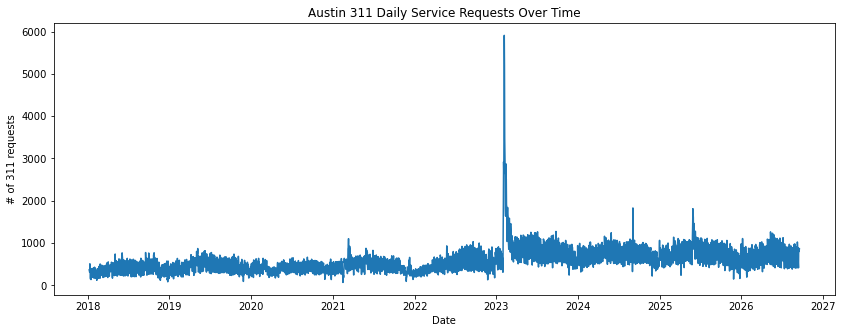

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(model_df['date'],model_df['311_requests'])

plt.title("Austin 311 Daily Service Requests Over Time")
plt.xlabel("Date")
plt.ylabel("# of 311 requests")

plt.show()

Those massive spikes on February 6th and 7th, 2023, were caused by the aftermath of Winter Storm Mara, a severe ice storm that hit Austin between January 30 and February 2, 2023. [https://storymaps.arcgis.com/stories/ce2d63e1e1c843c3a5ee2b6545bb1499]


The storm coated Austin in up to 0.69 inches of ice, which acted like a "hurricane-level" event for trees. The immense weight snapped millions of tree limbs across the city, downing power lines and knocking out electricity for over 170,000 Austin Energy customers

### II. What does demand look like by day of week?

In [99]:
weekday_demand = model_df.groupby('day_of_week')['311_requests'].mean()

weekday_demand

day_of_week
0    723.337004
1    738.191630
2    725.273128
3    705.623348
4    706.399558
5    472.863135
6    375.653422
Name: 311_requests, dtype: float64

In [101]:
weekday_names=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday","Sunday"]

weekday_demand.index = weekday_names

weekday_demand

Monday       723.337004
Tuesday      738.191630
Wednesday    725.273128
Thursday     705.623348
Friday       706.399558
Saturday     472.863135
Sunday       375.653422
Name: 311_requests, dtype: float64

Important: We cannot say yet that being a weekend "causes" fewer 311 requests.

All we can say from this EDA is: 311 demand is strongly associated with day of week, with substantially lower average demand on weekends in this dataset.

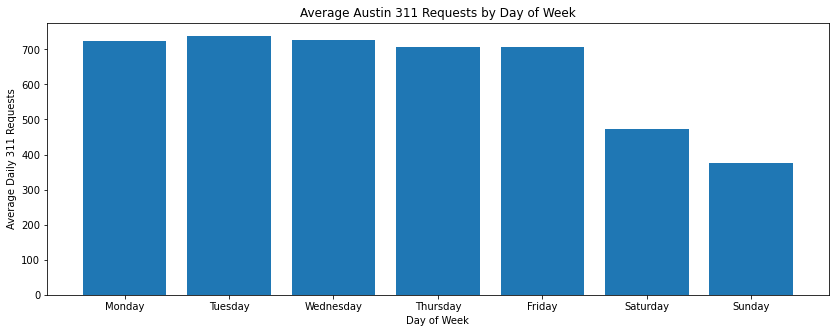

In [102]:
plt.figure(figsize=(14,5))

plt.bar(weekday_demand.index,weekday_demand.values)

plt.title("Average Austin 311 Requests by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily 311 Requests")

plt.show()

In [105]:
weekday_avg = model_df.loc[ model_df['is_weekend']==0, "311_requests"]. mean()

weekend_avg = model_df.loc[ model_df['is_weekend']==1, "311_requests"]. mean()

weekday_avg, weekend_avg

(719.7708241516086, 424.2582781456954)

**Weekday average: 719.8 requests/day

**Weekend average: 424.3 requests/day**

That's a difference of about 295.5 requests per day. Weekend demand is about **41% lower than weekday** demand in this dataset.

That's a descriptive finding, not a causal claim. There could be several reasons for it—operating patterns, resident behavior, reporting channels, service types, etc. Our regression will help us see whether the weekend pattern remains after accounting for other variables.

**Average daily 311 demand is substantially lower on weekends (424 requests) than on weekdays (720 requests), indicating a strong day-of-week pattern in the historical data.**

### III. Monthly seasonality

In [106]:
monthly_demand = model_df.groupby('month')['311_requests'].mean()

monthly_demand

month
1     524.312500
2     712.681102
3     633.046595
4     640.007407
5     701.652330
6     704.770370
7     670.383513
8     671.806452
9     671.268482
10    640.846774
11    534.933333
12    500.532258
Name: 311_requests, dtype: float64

In [108]:
month_names = ["January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December"]

monthly_demand.index=month_names

monthly_demand

January      524.312500
February     712.681102
March        633.046595
April        640.007407
May          701.652330
June         704.770370
July         670.383513
August       671.806452
September    671.268482
October      640.846774
November     534.933333
December     500.532258
Name: 311_requests, dtype: float64

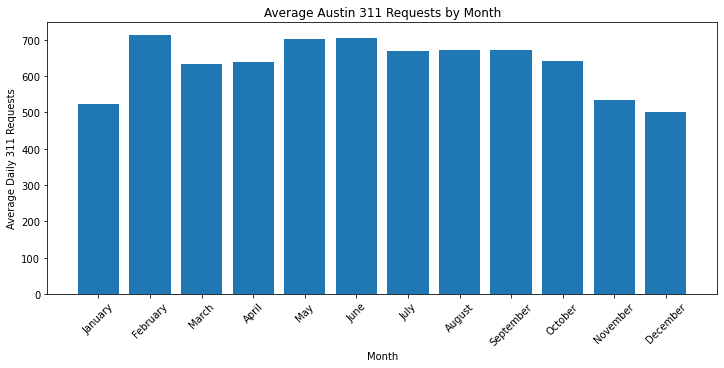

In [110]:
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_demand.index,
    monthly_demand.values
)

plt.title("Average Austin 311 Requests by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily 311 Requests")

plt.xticks(rotation=45)

plt.show()

February is unusually high: ~713/day.

May–June are also relatively high: ~702–705/day.

November–January are noticeably lower: ~501–535/day.

The middle of the year is generally around 640–705/day.

Unlike weekday effects, there's no simple monotonic seasonal trend.

February's high average may be partly influenced by unusual event periods, such as the February 2023 ice storm we just noticed. That's something we should be careful about before interpreting February as inherently a "high-demand month."

### IV. Weather: temperature vs. 311 demand

Are hotter or colder days associated with different levels of 311 demand?

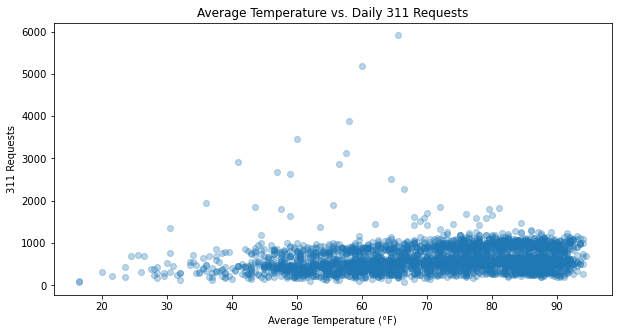

In [113]:
plt.figure(figsize=(10, 5))

plt.scatter(
    model_df["avg_temp_f"],
    model_df["311_requests"],
    alpha=0.3
)

plt.title("Average Temperature vs. Daily 311 Requests")
plt.xlabel("Average Temperature (°F)")
plt.ylabel("311 Requests")

plt.show()

Temperature has very little obvious linear relationship with daily 311 demand.

Most of the observations are packed between roughly 42°F and 95°F, while the request counts form a broad horizontal cloud.

In [114]:
# calculate the Pearson correlation between average temperature and 311 demand:
#close to +1 → strong positive linear relationship
#close to -1 → strong negative linear relationship
#close to 0 → little linear relationship

model_df['avg_temp_f'].corr(model_df['311_requests'])

0.1850037697312847

As average temperature increases, 311 requests tend to increase slightly — but the relationship is weak.

Average temperature showed a weak positive correlation with daily 311 demand (r = 0.185), suggesting that temperature alone explains relatively little of the variation in request volume.

In [116]:
r = model_df['avg_temp_f'].corr(model_df['311_requests'])

r_squared=r**2
r_squared

0.03422639481478622

Temperature alone explains about 3.4% of variation in daily demand

Weather alone doesn't explain much of Austin's daily 311 demand.

### V. Precipitation

In [118]:
model_df['precipitation_in'].corr(model_df['311_requests'])

0.006785075569163746

**Weather variables showed limited individual linear relationships with daily 311 demand. Average temperature had a weak positive correlation (r = 0.185), while precipitation showed virtually no linear correlation (r = 0.007). This suggests that calendar effects and historical demand may provide more useful predictive information than individual weather variables alone.**

### VI. Wind

In [120]:
model_df['avg_wind_mph'].corr(model_df['311_requests'])

0.03999595834470356

**There is no strong individual linear relationship between these weather variables and daily 311 demand.**

That doesn't mean weather is useless. A variable can still contribute to a multiple regression model even when its individual correlation is weak—especially when combined with calendar patterns and historical demand.

This completes our EDA. We'll save model_df, our final modeling-ready dataset, as CSV:

merging 311 + weather

calendar features

lag features

7-day rolling demand

handling missing rows

dropping the initial lag/rolling NaNs

It's currently 3,175 rows × 14 columns

In [123]:
model_df.to_csv('data/austin_311_model.csv', index=False)

# Part 3: Machine Learning Algorithms

### Stage 1: Split the modeling dataset chronologically

- 2018–2024: Training

- 2025: Test

- January–September 2026: Final holdout

In [25]:
model_df = pd.read_csv('data/austin_311_model.csv')
model_df.head()

,date,311_requests,avg_temp_f,max_temp_f,min_temp_f,precipitation_in,avg_wind_mph,day_of_week,is_weekend,month,year,lag_1,lag_7,rolling_7
0,2018-01-08,366,56.5,69,44,0.0,5.82,0,0,1,2018,204.0,162.0,260.714286
1,2018-01-09,362,54.5,70,39,0.0,2.68,1,0,1,2018,366.0,290.0,289.857143
2,2018-01-10,309,59.5,71,48,0.0,6.49,2,0,1,2018,362.0,355.0,300.142857
3,2018-01-11,509,58.0,72,44,0.0,7.61,3,0,1,2018,309.0,320.0,293.571429
4,2018-01-12,339,46.0,58,34,0.0,7.61,4,0,1,2018,509.0,274.0,320.571429


In [26]:
# 1. Training: 2018–2024
train_df = model_df[
    model_df["date"] < "2025-01-01"
].copy()


# 2. Testing: 2025
test_df = model_df[
    (model_df["date"] >= "2025-01-01") &
    (model_df["date"] < "2026-01-01")
].copy()


# 3. Final holdout: 2026
holdout_df = model_df[
    (model_df["date"] >= "2026-01-01") &
    (model_df["date"] < "2027-01-01")
].copy()

In [27]:
# Check dataset sizes and date ranges
for name, dataset in [
    ("Training", train_df),
    ("Testing", test_df),
    ("Final Holdout", holdout_df)
]:
    print(f"\n{name} Dataset")
    print("Shape:", dataset.shape)
    print("Start:", dataset["date"].min())
    print("End:", dataset["date"].max())


Training Dataset
Shape: (2550, 14)
Start: 2018-01-08
End: 2024-12-31

Testing Dataset
Shape: (365, 14)
Start: 2025-01-01
End: 2025-12-31

Final Holdout Dataset
Shape: (260, 14)
Start: 2026-01-01
End: 2026-09-17


### Stage 2: Model 1 — Persistence baseline

**Our assumption:** Today's 311 request count will be the same as yesterday's actual request count.

This is our benchmark. No model training, no coefficients, no statistical assumptions to estimate.

#### Step 2.1: Model 1: Persistence baseline

**Why are we using lag_1 from test_df?** Because lag_1 already contains the previous day's actual request count. We prepared that feature earlier when building model_df.

In [28]:
y_test = test_df["311_requests"]

persistence_predictions = test_df["lag_1"]

# View the first five predictions
comparison = pd.DataFrame({
    "Date": test_df["date"].head(),
    "Actual_Requests": y_test.head().values,
    "Predicted_Requests": persistence_predictions.head().values
})

comparison

,Date,Actual_Requests,Predicted_Requests
2550,2025-01-01,733,1063.0
2551,2025-01-02,815,733.0
2552,2025-01-03,883,815.0
2553,2025-01-04,661,883.0
2554,2025-01-05,593,661.0


#### Step 2.2 — Calculate baseline performance


- MAE: Average prediction error in requests per day.
- RMSE: Gives greater weight to large prediction errors.
- R²: Measures predictive performance relative to predicting the test-set mean.

In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
persistence_mae = mean_absolute_error(
    y_test, persistence_predictions
)

persistence_rmse = np.sqrt(
    mean_squared_error(y_test, persistence_predictions)
)

persistence_r2 = r2_score(
    y_test, persistence_predictions
)

print("Persistence Baseline Performance — 2025")
print("----------------------------------------")
print("MAE:", round(persistence_mae, 2))
print("RMSE:", round(persistence_rmse, 2))
print("R-squared:", round(persistence_r2, 3))

Persistence Baseline Performance — 2025
----------------------------------------
MAE: 180.71
RMSE: 245.56
R-squared: -0.083


**Step 2.3: Interpretation**
- Average absolute prediction error: approximately 181 requests per day.
- RMSE is higher than MAE, indicating some relatively large prediction errors.
- Negative R² means this baseline performed worse than predicting the average 2025 demand every day.

**Business interpretation:** Yesterday's request volume alone isn't sufficient to reliably estimate today's demand.

#### Model 1 – Persistence Baseline, record:
A persistence baseline was established by using the previous day's actual 311 service request count as the prediction for the current day. The model was evaluated on 365 observations from 2025, achieving an MAE of 180.71, RMSE of 245.56, and R² of -0.083. The results indicate that relying exclusively on the previous day's demand provides limited predictive value.

### Stage 3: Model 2 — Simple Linear Regression using Statsmodel

we'll train a proper simple linear regression model using:
- Target (Y): Today's 311_requests
- Predictor (X): Yesterday's lag_1

💡 WHY PERSISTENCE AND SIMPLE LINEAR REGRESSION ARE NOT THE SAME:

Even though both use yesterday's data (lag_1) as input, their math is entirely different:

1. Persistence Baseline (Naive): Blindly copies yesterday's value forward.

   Formula: Prediction = lag_1
   
   If yesterday = 100, today's prediction = 100. (Slope is locked at 1.0, Intercept at 0.0)


2. Simple Linear Regression: Scales and shifts yesterday's value using a line of best fit.
   
   Formula: Prediction = (Slope * lag_1) + Intercept
   
   If yesterday = 100, the trained model dampens anomalies and adjusts for baseline city volume.

 Regression outperforms persistence because its optimized weights protect it from overreacting to single-day extreme spikes.


#### Step 3.1 — Train the simple linear regression model

Business Question: Can yesterday's 311 demand help explain today's 311 demand?

In [30]:
import statsmodels.api as sm

# Select the independent and dependent variables
X_train = train_df[["lag_1"]]
y_train = train_df["311_requests"]

# Add the intercept (constant)
X_train = sm.add_constant(X_train)

# Train the model
simple_model = sm.OLS(y_train, X_train).fit()

# Display results
print(simple_model.summary())

                            OLS Regression Results                            
Dep. Variable:           311_requests   R-squared:                       0.652
Model:                            OLS   Adj. R-squared:                  0.652
Method:                 Least Squares   F-statistic:                     4773.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:05:34   Log-Likelihood:                -17004.
No. Observations:                2550   AIC:                         3.401e+04
Df Residuals:                    2548   BIC:                         3.402e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        114.7270      7.906     14.512      0.0

C:\Users\stanv\anaconda3\lib\site-packages\statsmodels\tsa\tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)


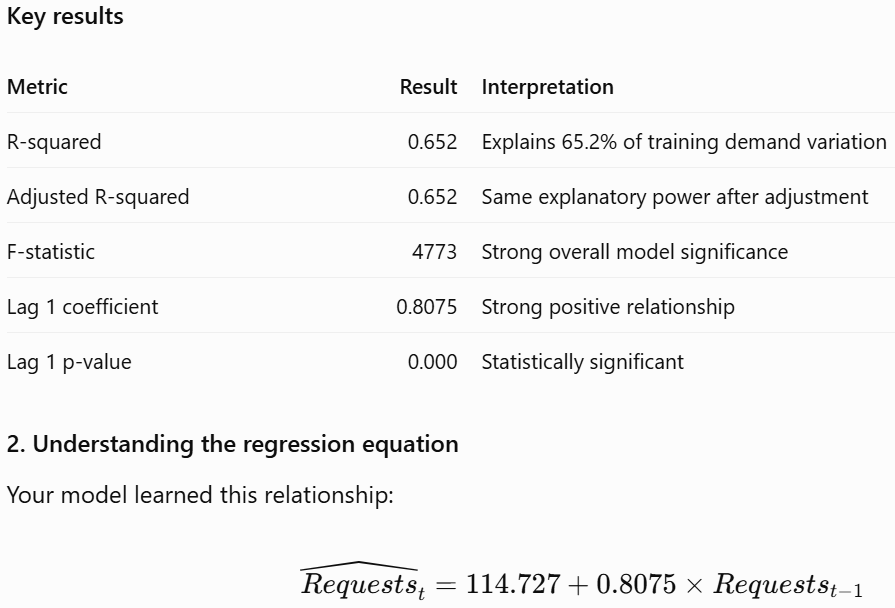

- Intercept (114.727): The estimated demand when the previous day's requests are zero.

- Coefficient (0.8075): For every additional 100 requests yesterday, the model estimates approximately 81 additional requests today. Strong positive relationship

1. Yesterday's demand has a strong positive relationship with today's demand.

2. The coefficient is statistically significant (p-value below 0.001).

3. The model explains 65.2% of variation in the training data. (r-squared)

#### Step 3.2 — Generate predictions on 2025 test data

In [33]:
X_test = test_df[["lag_1"]]
X_test = sm.add_constant(X_test)

simple_predictions = simple_model.predict(X_test)

# Compare actual and predicted values
simple_comparison = pd.DataFrame({
    "Date": test_df["date"],
    "Actual_Requests": test_df["311_requests"],
    "Predicted_Requests": simple_predictions
})

simple_comparison.head()

,Date,Actual_Requests,Predicted_Requests
2550,2025-01-01,733,973.143680
2551,2025-01-02,815,706.654956
2552,2025-01-03,883,772.873366
2553,2025-01-04,661,827.786194
2554,2025-01-05,593,648.511962


In [34]:
simple_comparison.head().reset_index(drop=True)

,Date,Actual_Requests,Predicted_Requests
0,2025-01-01,733,973.143680
1,2025-01-02,815,706.654956
2,2025-01-03,883,772.873366
3,2025-01-04,661,827.786194
4,2025-01-05,593,648.511962


#### Step 3.3 — Evaluate Simple Linear Regression on 2025 test data

In [35]:
simple_mae = mean_absolute_error(
    y_test, simple_predictions
)

simple_rmse = np.sqrt(
    mean_squared_error(y_test, simple_predictions)
)

simple_r2 = r2_score(
    y_test, simple_predictions
)

print("Simple Linear Regression Performance — 2025")
print("--------------------------------------------")
print("MAE:", round(simple_mae, 2))
print("RMSE:", round(simple_rmse, 2))
print("R-squared:", round(simple_r2, 3))

Simple Linear Regression Performance — 2025
--------------------------------------------
MAE: 172.37
RMSE: 229.28
R-squared: 0.056


**Step 3.4: Interpretation**

- MAE: 172.37 | On average, the model's predictions differ from actual daily demand by approximately 172 requests.

- RMSE: 229.28 | The larger RMSE indicates that some predictions have considerably larger errors than others.

- R²: 0.056 | The model explains only 5.6% of the variation in the 2025 test data. This is quite low.

**Business interpretation:** Although yesterday's demand explains 65.2% of variation in the training data, it does not generalize particularly well to 2025. 

In [36]:
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Simple Linear Regression"
    ],
    "MAE": [
        persistence_mae,
        simple_mae
    ],
    "RMSE": [
        persistence_rmse,
        simple_rmse
    ],
    "R2": [
        persistence_r2,
        simple_r2
    ]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,180.707,245.561,-0.083
1,Simple Linear Regression,172.374,229.275,0.056


#### Model 2: Simple Linear Regression, record:

A simple linear regression model was developed using the previous day's 311 request count (lag_1) as the sole predictor. The model was trained on 2,550 observations from 2018–2024 and evaluated on 365 observations from 2025.

The training R-squared was 0.652, indicating that the model explained 65.2% of the variation in training demand. On the 2025 test dataset, it achieved an MAE of 172.37, RMSE of 229.28, and R-squared of 0.056.

Although the model marginally outperformed the persistence baseline, its predictive performance on unseen data remained limited. This suggests that yesterday's demand alone may not capture the calendar patterns and other factors influencing daily 311 service demand.

### Stage 4: Model 3 — Multiple Linear Regression using Statsmodel

We'll train a proper multiple linear regression model using:
- Target (Y): Today's 311_requests
- Predictor (X): 
        -- lag_1: Previous day's demand.
        -- lag_7: Demand seven days earlier.
        -- rolling_7: Average demand over the previous seven days.
        -- day_of_week: Day-of-week patterns.
        -- month: Monthly patterns.
        -- avg_temp_f: Average temperature.
        -- precipitation_in: Precipitation.
        -- avg_wind_mph: Average wind speed.

**Note:**
We'll use dummy variables for 'day_of_week' and 'month' as they are categorical variables, not continuous measurements.

For example, Sunday (6) isn't twice Wednesday (2). So we convert these categories into separate binary columns.
- drop_first=True removes one category to avoid redundant columns.
- Monday and January become the reference categories.
- The other categories are measured relative to those reference categories.

Deliberately excluding:
- year: We don't want the model to simply learn a time trend.
- is_weekend: It's redundant because day_of_week already captures weekends.

#### Step 4.1 — Train the multiple linear regression model

Business Question: Can we improve our understanding of daily 311 demand by combining historical demand, calendar patterns, and weather variables?

In [37]:
import statsmodels.api as sm

# Select independent variables
X_train_multi = train_df[
    [
        "lag_1",
        "lag_7",
        "rolling_7",
        "day_of_week",
        "month",
        "avg_temp_f",
        "precipitation_in",
        "avg_wind_mph"
    ]
]

# Select dependent variable
y_train_multi = train_df["311_requests"]

# Convert categorical variables into dummy variables
X_train_multi = pd.get_dummies(
    X_train_multi,
    columns=["day_of_week", "month"],
    drop_first=True,
    dtype=int
)

# Add intercept
X_train_multi = sm.add_constant(X_train_multi)

# Train the model
multiple_model = sm.OLS(
    y_train_multi,
    X_train_multi
).fit()

# Display results
print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:           311_requests   R-squared:                       0.847
Model:                            OLS   Adj. R-squared:                  0.845
Method:                 Least Squares   F-statistic:                     606.1
Date:                Wed, 04 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:07:23   Log-Likelihood:                -15960.
No. Observations:                2550   AIC:                         3.197e+04
Df Residuals:                    2526   BIC:                         3.211e+04
Df Model:                          23                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const              244.4377     22.101  

C:\Users\stanv\anaconda3\lib\site-packages\statsmodels\tsa\tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)


A multiple linear regression model was developed using historical demand, calendar features, and weather variables. The predictors included previous-day demand, demand from seven days earlier, a seven-day rolling average, day of week, month, average temperature, precipitation, and wind speed.


Categorical variables were converted into dummy variables, using Monday and January as reference categories. The model was trained on 2,550 observations covering 2018–2024.


The model achieved a training R-squared of 0.847 and adjusted R-squared of 0.845, explaining approximately 84.7% of the variation in training demand. Historical demand and day-of-week variables showed particularly strong statistical associations with daily requests. Most monthly indicators and the seven-day rolling average were not individually significant at the 5% level.


Residual diagnostics indicated substantial non-normality and potential numerical or multicollinearity concerns. These limitations were considered when interpreting the model.

#### Step 4.2 — Generate predictions on 2025 test data

In [38]:
X_test_multi = test_df[
    [
        "lag_1",
        "lag_7",
        "rolling_7",
        "day_of_week",
        "month",
        "avg_temp_f",
        "precipitation_in",
        "avg_wind_mph"
    ]
]

# Convert categorical variables into dummy variables
X_test_multi = pd.get_dummies(
    X_test_multi,
    columns=["day_of_week", "month"],
    drop_first=True,
    dtype=int
)

# Match test columns with training columns
X_test_multi = X_test_multi.reindex(
    columns=X_train_multi.columns,
    fill_value=0
)

#Using reindex() step?:The model was trained with a particular set and order of columns. 
#We must ensure the 2025 data has precisely the same columns in precisely the same order.

# Generate predictions
multiple_predictions = multiple_model.predict(X_test_multi)

In [39]:
# Create comparison of actual and predicted values

multiple_comparison = pd.DataFrame({
    "Date": test_df["date"].values,
    "Actual_Requests": test_df["311_requests"].values,
    "Predicted_Requests": multiple_predictions
})

multiple_comparison.head()

,Date,Actual_Requests,Predicted_Requests
2550,2025-01-01,733,694.173969
2551,2025-01-02,815,453.438782
2552,2025-01-03,883,544.116330
2553,2025-01-04,661,396.118830
2554,2025-01-05,593,280.300183


#### Step 4.3 — Evaluate Multiple Linear Regression on 2025 test data

In [40]:
multiple_mae = mean_absolute_error(y_test, multiple_predictions)

multiple_rmse = np.sqrt(
    mean_squared_error(y_test, multiple_predictions)
)

multiple_r2 = r2_score(y_test, multiple_predictions)

print("Multiple Linear Regression Performance — 2025")
print("----------------------------------------------")
print("MAE:", round(multiple_mae, 2))
print("RMSE:", round(multiple_rmse, 2))
print("R-squared:", round(multiple_r2, 3))

Multiple Linear Regression Performance — 2025
----------------------------------------------
MAE: 262.54
RMSE: 288.07
R-squared: -0.491


In [41]:
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Simple Linear Regression",
        "Multiple Linear Regression"
    ],
    "MAE": [
        persistence_mae,
        simple_mae,
        multiple_mae
    ],
    "RMSE": [
        persistence_rmse,
        simple_rmse,
        multiple_rmse
    ],
    "R2": [
        persistence_r2,
        simple_r2,
        multiple_r2
    ]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,180.707,245.561,-0.083
1,Simple Linear Regression,172.374,229.275,0.056
2,Multiple Linear Regression,262.543,288.075,-0.491


**Lower MAE and RMSE are better; higher R² is better.**

The multiple regression model performed worse than both simpler models on the 2025 test data.

#### Step 4.4: Investigation:

4.4.1 Check actual vs. predicted demand

In [42]:
#Check actual vs. predicted demand

prediction_check = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": np.asarray(multiple_predictions)
})

prediction_check["Error"] = (
    prediction_check["Actual"] - prediction_check["Predicted"]
)

print("2025 Actual vs. Predicted Demand")
print("--------------------------------")
print(prediction_check.describe().round(2))

print("\nAverage prediction error:", round(prediction_check["Error"].mean(), 2))

2025 Actual vs. Predicted Demand
--------------------------------
        Actual  Predicted   Error
count   365.00     365.00  365.00
mean    818.99     559.69  259.30
std     236.27     196.76  125.67
min     148.00     -11.30 -243.59
25%     654.00     445.02  187.12
50%     874.00     586.03  243.45
75%     979.00     686.92  326.65
max    1812.00    1421.50  749.95

Average prediction error: 259.3


4.4.2 Calculate Variance Inflation Factor (VIF)

VIF helps us identify whether predictors are strongly explained by combinations of other predictors.

A common interpretation:

- 1	No multicollinearity
- 1–5	Generally acceptable
- 5–10	Potential concern
- Above 10	High multicollinearity

In [43]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Feature"] = X_train_multi.columns

vif_data["VIF"] = [
    variance_inflation_factor(
        X_train_multi.values, i
    )
    for i in range(X_train_multi.shape[1])
]

vif_data = vif_data[vif_data["Feature"] != "const"]

vif_data = vif_data.sort_values(
    by="VIF", ascending=False
)

vif_data.round(2)

,Feature,VIF
3,rolling_7,12.45
1,lag_1,6.23
2,lag_7,6.21
4,avg_temp_f,3.98
19,month_8,3.71
18,month_7,3.60
17,month_6,3.29
20,month_9,3.13
16,month_5,2.84
8,day_of_week_2,2.54


#### Step 4.5: Train & Test model without rolling_7
Let's remove rolling_7

In [44]:
# 1. Prepare training predictors without rolling_7
reduced_features = [
    "lag_1",
    "lag_7",
    "day_of_week",
    "month",
    "avg_temp_f",
    "precipitation_in",
    "avg_wind_mph"
]

X_train_reduced = train_df[reduced_features].copy()
y_train_reduced = train_df["311_requests"]

# Convert categorical variables into dummy variables
X_train_reduced = pd.get_dummies(
    X_train_reduced,
    columns=["day_of_week", "month"],
    drop_first=True,
    dtype=int
)

X_train_reduced = sm.add_constant(X_train_reduced)

# 2. Train the reduced model
reduced_model = sm.OLS(
    y_train_reduced,
    X_train_reduced
).fit()

# 3. Prepare 2025 test predictors
X_test_reduced = test_df[reduced_features].copy()

X_test_reduced = pd.get_dummies(
    X_test_reduced,
    columns=["day_of_week", "month"],
    drop_first=True,
    dtype=int
)

X_test_reduced = X_test_reduced.reindex(
    columns=X_train_reduced.columns,
    fill_value=0
)

# 4. Generate predictions
reduced_predictions = reduced_model.predict(X_test_reduced)

# 5. Evaluate performance
reduced_mae = mean_absolute_error(y_test, reduced_predictions)
reduced_rmse = np.sqrt(mean_squared_error(y_test, reduced_predictions))
reduced_r2 = r2_score(y_test, reduced_predictions)

print("Reduced Multiple Regression — 2025")
print("-----------------------------------")
print("Training R-squared:", round(reduced_model.rsquared, 3))
print("MAE:", round(reduced_mae, 2))
print("RMSE:", round(reduced_rmse, 2))
print("R-squared:", round(reduced_r2, 3))

Reduced Multiple Regression — 2025
-----------------------------------
Training R-squared: 0.847
MAE: 265.34
RMSE: 290.77
R-squared: -0.519


C:\Users\stanv\anaconda3\lib\site-packages\statsmodels\tsa\tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)


In [45]:
print("Training period:")
print("Mean demand:", round(train_df["311_requests"].mean(), 2))
print("Mean lag_1:", round(train_df["lag_1"].mean(), 2))
print("Correlation:", round(
    train_df["lag_1"].corr(train_df["311_requests"]), 3
))

print("\n2025 Testing period:")
print("Mean demand:", round(test_df["311_requests"].mean(), 2))
print("Mean lag_1:", round(test_df["lag_1"].mean(), 2))
print("Correlation:", round(
    test_df["lag_1"].corr(test_df["311_requests"]), 3
))

Training period:
Mean demand: 594.7
Mean lag_1: 594.36
Correlation: 0.807

2025 Testing period:
Mean demand: 818.99
Mean lag_1: 819.22
Correlation: 0.459


Three important observations:
1. Demand level increased: Average daily demand was approximately 38% higher in 2025.
2. Lag relationship weakened: Correlation dropped from 0.807 to 0.459.
3. The model learned an older pattern: It learned that yesterday's demand was a strong predictor, but that relationship became considerably weaker in 2025.


This is a classic textbook example of **Concept drift**

**Concept drift** occurs when the statistical properties of your target variable change over time in an unforeseen way.

Think of a machine learning model like a weather forecaster. If the forecaster learns how rain works in California, but you suddenly move them to a tropical rainforest, their old rules will completely fail. The "concept" of what drives rain has drifted.

In our data, the fundamental relationship between yesterday's volume (lag_1) and today's volume (311_requests) has broken down:

- In Training: Yesterday was an excellent predictor of today (Correlation = 0.807). The model leaned heavily on this rule.

- In Testing: The relationship weakened drastically (Correlation dropped to 0.459). The rule your model spent all its time learning suddenly stopped working in the real world.


Let's determine whether demand increased gradually or whether there was a sudden change in a particular year.

In [46]:
yearly_analysis = (
    model_df.groupby("year")
    .agg(
        Average_Daily_Requests=("311_requests", "mean"),
        Average_Lag_1=("lag_1", "mean")
    )
)

yearly_correlation = (
    model_df.groupby("year")
    .apply(lambda group: group["lag_1"].corr(group["311_requests"]))
)

yearly_analysis["Lag_1_Correlation"] = yearly_correlation

yearly_analysis.round(3)

,Average_Daily_Requests,Average_Lag_1,Lag_1_Correlation
year,,,
2018,417.796,417.346,0.436
2019,488.375,488.288,0.446
2020,433.074,433.213,0.363
2021,497.455,497.773,0.571
2022,560.038,558.285,0.605
2023,970.375,970.186,0.827
2024,792.292,791.954,0.349
2025,818.992,819.216,0.459
2026,777.392,777.846,0.360


**Finding 1: Daily demand has changed considerably over the years.**

2023 stands out, with average daily demand increasing substantially compared with 2022. Demand subsequently decreased in 2024 and remained elevated in 2025 and 2026.

This matters because our model trained on 2018–2024 learned from years with substantially different demand levels.

**Finding 2: The relationship between yesterday's demand and today's demand is inconsistent.**

The correlation was particularly strong in 2023, but weakened substantially in 2024.

This is important: our training period combines years with very different relationships between yesterday's and today's demand.


**Conclusion**: 
- Key analytical finding

Austin 311 daily service demand varied substantially across years, and the strength of the relationship between consecutive days also changed over time. Models trained on historical demand patterns therefore did not generalize consistently to the 2025 test period.

- Business implication

Historical demand alone may not be sufficient for reliable daily demand forecasting. Model performance should be evaluated across different time periods before operational use.

#### Model Comparison:

In [47]:
model_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Simple Linear Regression",
        "Multiple Linear Regression",
        "Reduced Multiple Regression"
    ],
    "MAE": [
        persistence_mae,
        simple_mae,
        multiple_mae,
        reduced_mae
    ],
    "RMSE": [
        persistence_rmse,
        simple_rmse,
        multiple_rmse,
        reduced_rmse
    ],
    "R2": [
        persistence_r2,
        simple_r2,
        multiple_r2,
        reduced_r2
    ]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2
0,Persistence Baseline,180.707,245.561,-0.083
1,Simple Linear Regression,172.374,229.275,0.056
2,Multiple Linear Regression,262.543,288.075,-0.491
3,Reduced Multiple Regression,265.339,290.770,-0.519


### Stage 5: Evaluate the 2026 final holdout


Will use 'Simple Linear Regression' as it:

- performed best across all three metrics.

- reduced average absolute prediction error by approximately 4.6% compared with persistence.

In [48]:
# Prepare 2026 holdout predictors
X_holdout = holdout_df[["lag_1"]]

# Add intercept
X_holdout = sm.add_constant(X_holdout)

# Generate predictions
holdout_predictions = simple_model.predict(X_holdout)

# Actual values
y_holdout = holdout_df["311_requests"]

# Calculate performance metrics
holdout_mae = mean_absolute_error(
    y_holdout, holdout_predictions
)

holdout_rmse = np.sqrt(
    mean_squared_error(y_holdout, holdout_predictions)
)

holdout_r2 = r2_score(
    y_holdout, holdout_predictions
)

print("Simple Linear Regression — 2026 Final Holdout")
print("----------------------------------------------")
print("MAE:", round(holdout_mae, 2))
print("RMSE:", round(holdout_rmse, 2))
print("R-squared:", round(holdout_r2, 3))

Simple Linear Regression — 2026 Final Holdout
----------------------------------------------
MAE: 167.59
RMSE: 233.2
R-squared: -0.095


C:\Users\stanv\anaconda3\lib\site-packages\statsmodels\tsa\tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)


#### Interpretation:

- MAE: The model's predictions were off by approximately 168–172 requests per day on average.

- RMSE: Larger prediction errors had a noticeable impact on overall performance.

- R²: The model explained only a small amount of variation in 2025 and performed worse than simply predicting the average demand in 2026.

**Key finding**

- Historical daily demand provides some information about the following day's 311 requests, but the relationship does not translate into consistently reliable predictions across different time periods.

- The simple regression model modestly outperformed the persistence baseline in 2025, but its 2026 holdout R² was negative. The multiple regression model also performed poorly on unseen 2025 data despite its strong training performance.

**Business implication**

- Historical demand alone may not be sufficient for reliable daily service-demand forecasting. 

- Before operational use, models should demonstrate consistent performance across different time periods and meet an acceptable prediction-error threshold.

**Recommendation**

- Do not recommend the current models for operational forecasting. Treat the simple regression model as a benchmark for future development. 

- Additional operational information, such as request categories, unresolved backlog, holidays, events and staffing, could be explored in a future version.

# Part 4: Final verdict

### Project Objective

The objective of this project was to investigate whether historical Austin 311 service requests, calendar patterns, and weather conditions could help explain and predict daily service demand.

The analysis used more than 2 million 311 service records, integrated with daily weather data from NOAA. Three prediction approaches were evaluated using chronological data splits.

### Key Findings

1. **Demand patterns:** Daily 311 request volumes varied considerably across weekdays, weekends, and months. Weekday demand was approximately 41% higher than weekend demand.

2. **Historical demand:** Previous-day request volume provided useful information about the following day's demand, although the strength of this relationship varied across years.

3. **Model performance:** Simple Linear Regression modestly outperformed the persistence baseline in the 2025 test period. However, its performance remained limited, with an R² of 0.056 in 2025 and -0.095 in the 2026 holdout period.

4. **Model generalization:** Multiple Linear Regression achieved an R² of 0.847 on training data but performed substantially worse on unseen 2025 data. This highlights the importance of chronological evaluation rather than relying on training performance alone.

### Model Performance Summary

| Model | 2025 MAE | 2025 RMSE | 2025 R² |
|---|---:|---:|---:|
| Persistence Baseline | 180.71 | 245.56 | -0.083 |
| Simple Linear Regression | 172.37 | 229.28 | 0.056 |
| Multiple Linear Regression | 262.54 | 288.07 | -0.491 |

The Simple Linear Regression model was selected as the best-performing candidate based on the 2025 comparison. Its final evaluation on the 2026 holdout produced an MAE of 167.59, RMSE of 233.20, and R² of -0.095.

### Business Recommendations

- **Avoid immediate operational deployment:** The evaluated models do not demonstrate sufficiently reliable predictive performance for operational demand planning.
- **Use historical patterns for planning insights:** Weekday and weekend demand differences can help inform service-demand monitoring and resource discussions.
- **Evaluate models across time periods:** Model performance should be assessed on unseen data to identify changes in demand patterns and limitations in generalization.
- **Expand data sources in future work:** Future analysis could incorporate request categories, unresolved service backlogs, holidays, major events, and staffing information.

### Limitations

- The analysis is observational and identifies statistical relationships, not causal effects.
- The one-day-ahead predictions use the previous day's actual request volume.
- The 2026 evaluation covers January 1 through September 17, 2026, rather than a complete calendar year.
- The available features may not capture all factors influencing daily service demand.

### Final Takeaway

This project demonstrates that analyzing large public datasets can reveal meaningful service-demand patterns, but a model with strong training performance is not necessarily reliable on future data. Historical demand and weather provide a starting point for analysis, but more comprehensive operational data and consistent out-of-sample performance are needed before using predictive models to support real-world resource planning.

#### Extra: 
##### Temporal Instability and Potential Concept Drift

The analysis revealed substantial variation in annual demand levels and in the relationship between consecutive days' service request volumes. This suggests potential temporal instability and is consistent with the possibility of concept drift.

However, concept drift was not formally tested in this project. The findings highlight why models trained on historical data should be evaluated across different time periods before being considered for operational use.